***Performance on experiment "9fea1263-540e-4cc6-ad49-9e80276dca2b"***

Training reads were selected from this experiment, `./Data/synthetics/split_dict.pkl` contains how the reads are distributted betwee train/val/test subsets.

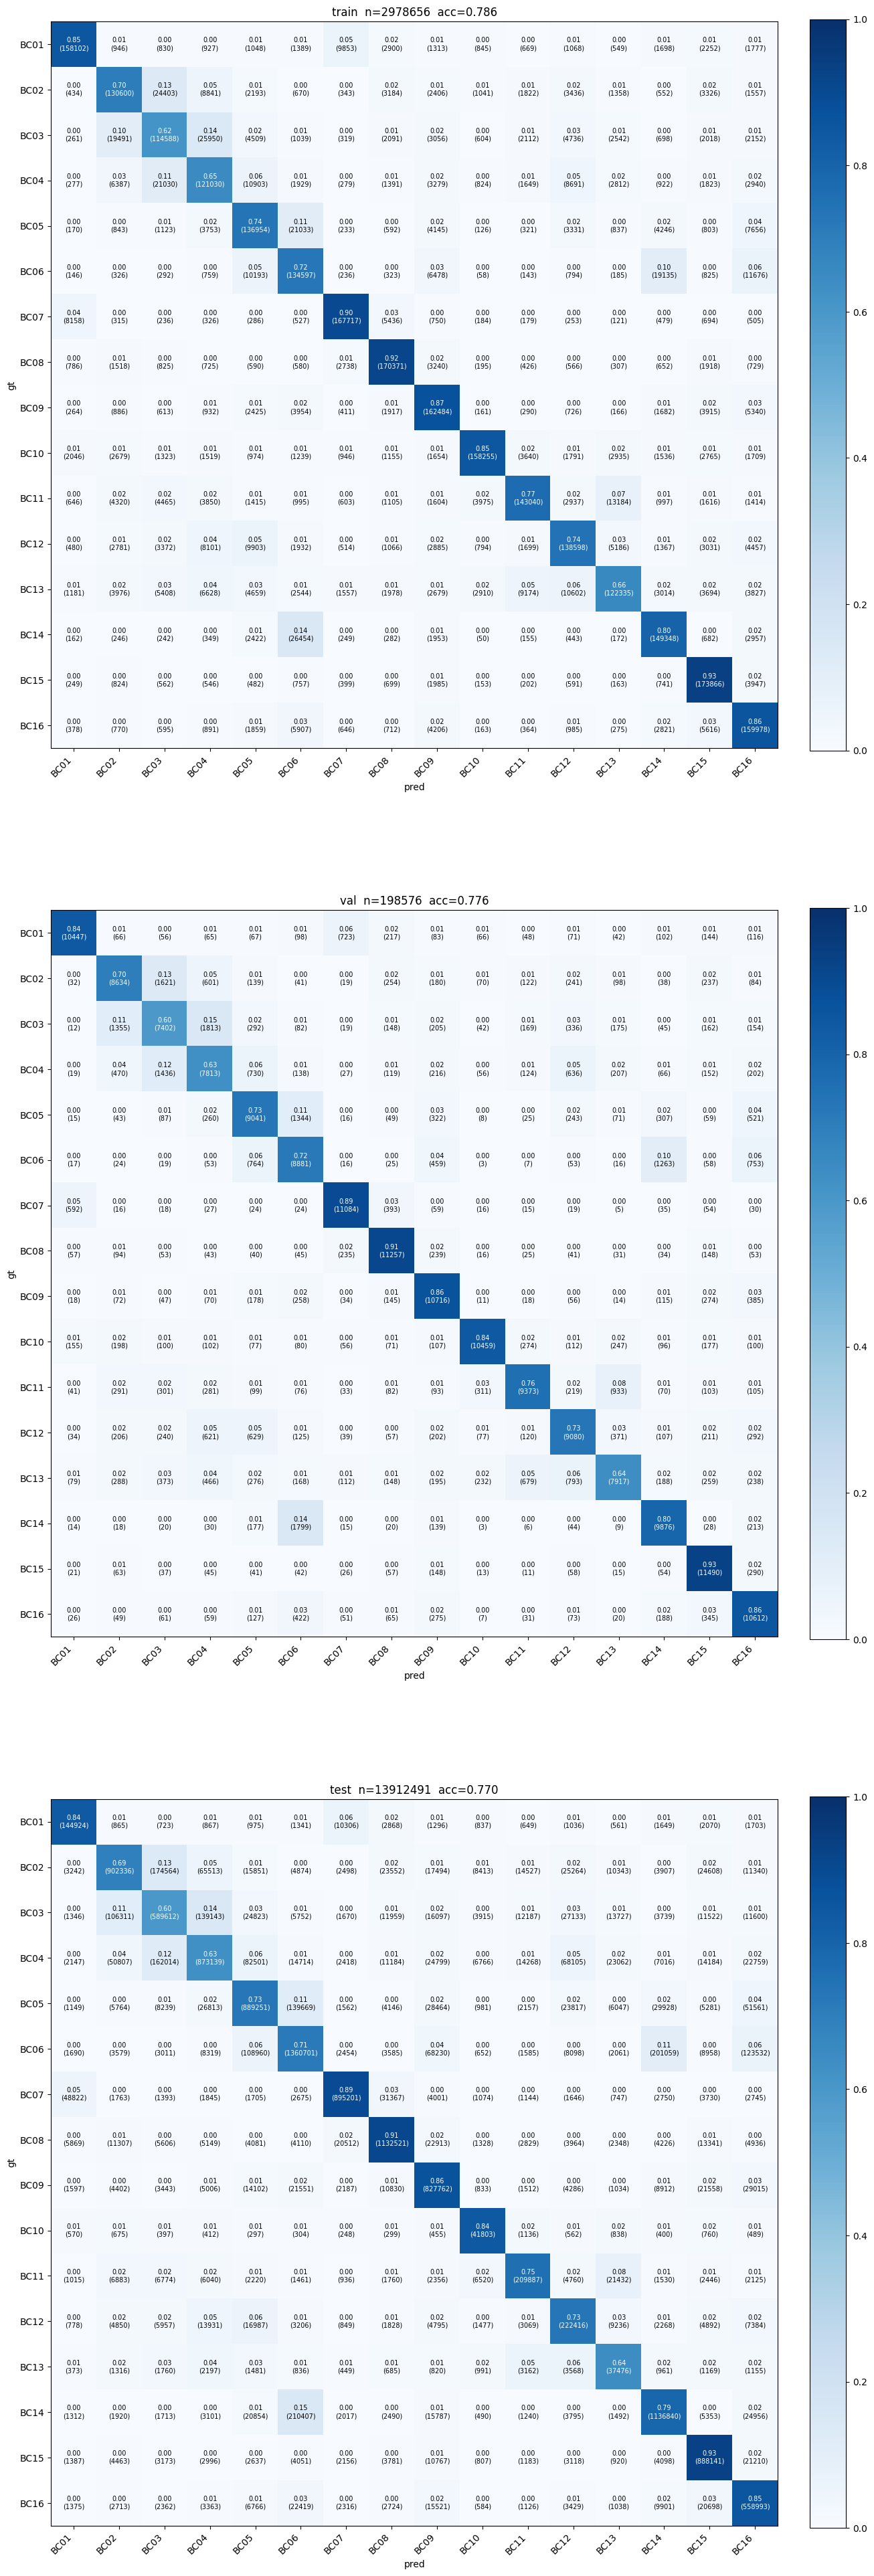

In [1]:
import pickle
import numpy as np
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

SPLIT_RIDS = "./Data/synthetics/split_dict.pkl"
PREDS = "./Data/results/9fea1263-540e-4cc6-ad49-9e80276dca2b.pkl"
NUM_CLASSES = 16
labels = list(range(NUM_CLASSES))
tick_labels = [f"BC{c+1:02d}" for c in labels]   # 0->BC01 ... 15->BC16

with open(SPLIT_RIDS, "rb") as fh:
    split_rids = pickle.load(fh)
with open(PREDS, "rb") as fh:
    preds = pickle.load(fh)

fig, axes = plt.subplots(3, 1, figsize=(13, 40))
for ax, name in zip(axes, ["train", "val", "test"]):
    gts, prs, missing = [], [], 0
    for rid in split_rids[name]:
        rec = preds.get(rid)
        if rec is None:
            missing += 1; continue
        gts.append(rec["gt"]); prs.append(rec["pred"])
    gt, pr = np.array(gts), np.array(prs)
    acc = (gt == pr).mean() if len(gt) else float("nan")

    cm = confusion_matrix(gt, pr, labels=labels)
    row_sums = cm.sum(axis=1, keepdims=True)
    recall = np.divide(cm, row_sums, where=row_sums != 0)
    recall[row_sums[:, 0] == 0] = 0

    im = ax.imshow(recall, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(labels); ax.set_yticks(labels)
    ax.set_xticklabels(tick_labels, rotation=45, ha="right")
    ax.set_yticklabels(tick_labels)
    ax.set_xlabel("pred"); ax.set_ylabel("gt")
    ax.set_title(f"{name}  n={len(gt)}  acc={acc:.3f}" +
                 (f"  (missing {missing})" if missing else ""))

    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            r = recall[i, j]
            c = cm[i, j]
            txt = f"{r:.2f}\n({c})"
            ax.text(j, i, txt, ha="center", va="center", fontsize=7,
                    color="white" if r > 0.5 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout(); plt.show()

***Performance on experiment "266e1025-91a2-48d9-a168-6386828065f6"***

Training reads were selected from this experiment, `./Data/synthetics/split_dict.pkl` contains how the reads are distributted betwee train/val/test subsets.

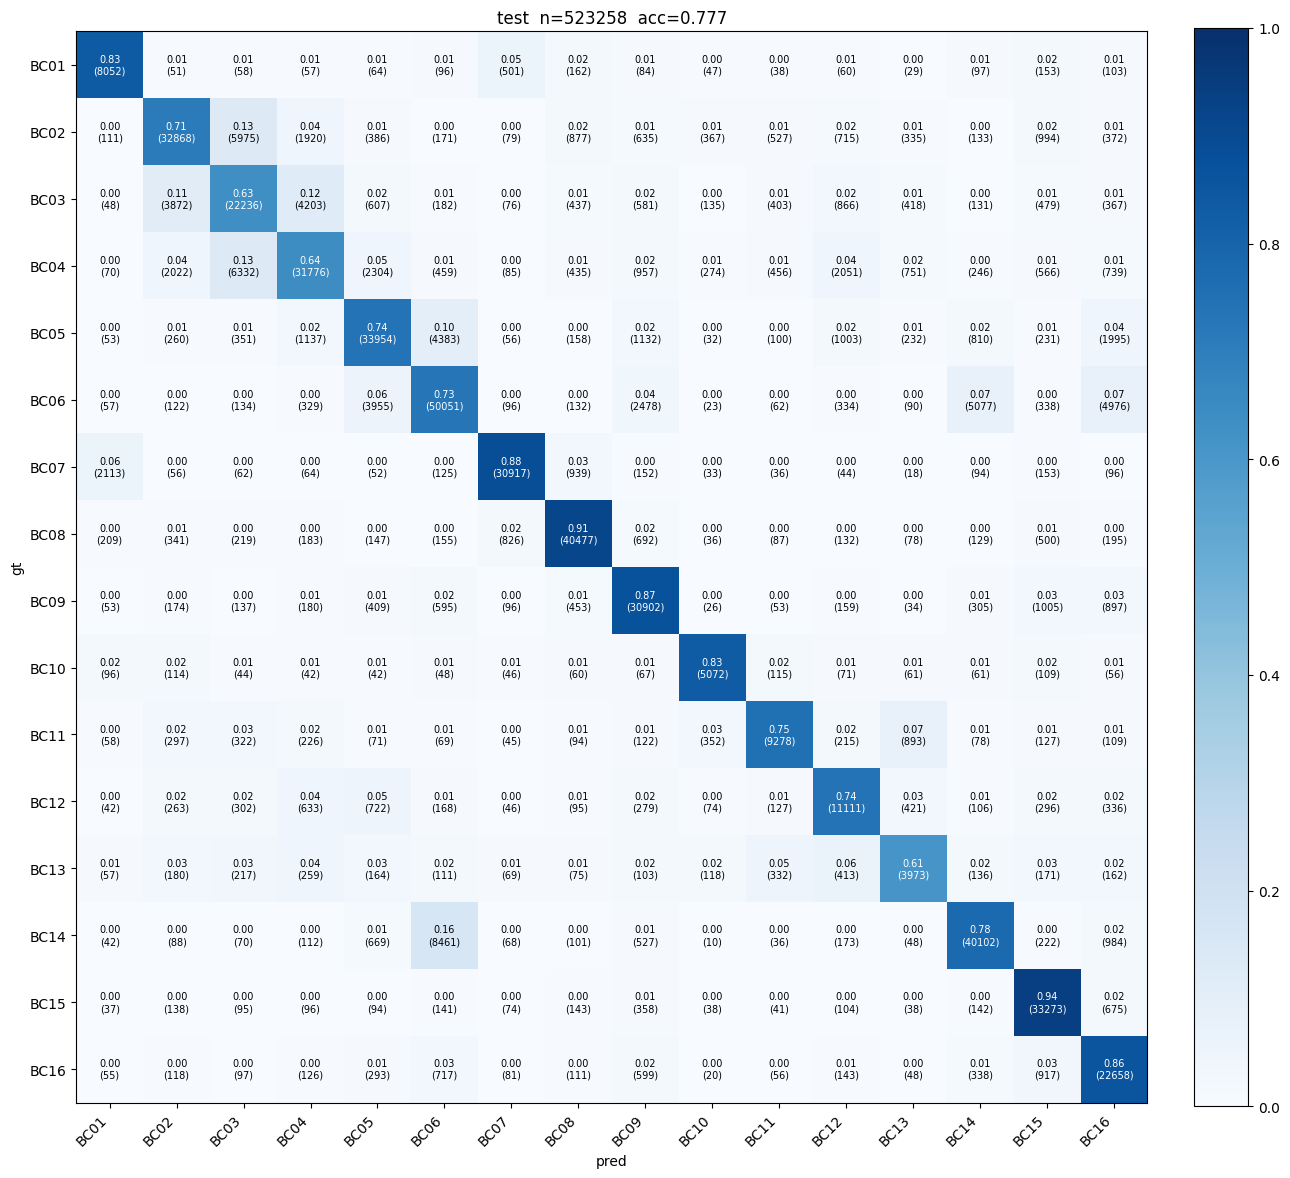

In [2]:
import pickle
import numpy as np
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

PREDS = "./Data/results/266e1025-91a2-48d9-a168-6386828065f6.pkl"
NUM_CLASSES = 16
labels = list(range(NUM_CLASSES))
tick_labels = [f"BC{c+1:02d}" for c in labels]   # 0->BC01 ... 15->BC16

with open(PREDS, "rb") as fh:
    preds = pickle.load(fh)

fig, axes = plt.subplots(1, 1, figsize=(13, 13))
axes = [axes,]
for ax, name in zip(axes, ["test"]):
    gts, prs, missing = [], [], 0
    for rid in preds.keys():
        rec = preds.get(rid)
        if rec is None:
            missing += 1; continue
        gts.append(rec["gt"]); prs.append(rec["pred"])
    gt, pr = np.array(gts), np.array(prs)
    acc = (gt == pr).mean() if len(gt) else float("nan")

    cm = confusion_matrix(gt, pr, labels=labels)
    row_sums = cm.sum(axis=1, keepdims=True)
    recall = np.divide(cm, row_sums, where=row_sums != 0)
    recall[row_sums[:, 0] == 0] = 0

    im = ax.imshow(recall, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(labels); ax.set_yticks(labels)
    ax.set_xticklabels(tick_labels, rotation=45, ha="right")
    ax.set_yticklabels(tick_labels)
    ax.set_xlabel("pred"); ax.set_ylabel("gt")
    ax.set_title(f"{name}  n={len(gt)}  acc={acc:.3f}" +
                 (f"  (missing {missing})" if missing else ""))

    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            r = recall[i, j]
            c = cm[i, j]
            txt = f"{r:.2f}\n({c})"
            ax.text(j, i, txt, ha="center", va="center", fontsize=7,
                    color="white" if r > 0.5 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout(); plt.show()